In [ ]:
# q1
import pandas as pd
import numpy as np

df = pd.read_csv("Titanic-Dataset.csv")

# --- Detect missing values ---
missing_counts = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)

missing_summary = pd.DataFrame(
    {"Missing Count": missing_counts, "Missing %": missing_pct}
)
missing_summary = missing_summary[missing_summary["Missing Count"] > 0]

print("=== Missing Value Summary ===")
print(missing_summary)
print(f"\nOriginal shape: {df.shape}")

# --- Strategy 1
df_drop_rows = df[df["Age"].notna() & df["Embarked"].notna()].copy()
print(f"\n[Strategy 1 - Row Removal]")
print(f"  Rows kept: {df_drop_rows.shape[0]} / {df.shape[0]}")
print(f"  Data retained: {df_drop_rows.shape[0]/df.shape[0]*100:.1f}%")

# --- Strategy 2
threshold = 40
cols_to_keep = missing_pct[missing_pct <= threshold].index.tolist()
cols_to_keep += [c for c in df.columns if c not in missing_pct.index]
df_drop_cols = df[list(dict.fromkeys(df.columns[df.columns.isin(cols_to_keep)]))].copy()
print(f"\n[Strategy 2 - Column Removal (threshold={threshold}%)]")
print(f"  Columns dropped: {[c for c in df.columns if c not in df_drop_cols.columns]}")
print(f"  Shape: {df_drop_cols.shape}")

# ---  Imputation ---
df_imputed = df.copy()


age_median = df_imputed["Age"].median()
df_imputed["Age"] = df_imputed["Age"].fillna(age_median)

df_imputed["Embarked"] = df_imputed["Embarked"].fillna(df_imputed["Embarked"].mode()[0])


df_imputed.drop(columns=["Cabin"], inplace=True)

print(f"\n[Strategy 3 - Imputation]")
print(f"  Age filled with median = {age_median}")
print(f"  Embarked filled with mode = '{df['Embarked'].mode()[0]}'")
print(f"  Cabin column dropped (77% missing)")
print(f"  Remaining missing values: {df_imputed.isnull().sum().sum()}")


print("\n=== Strategy Comparison ===")
comparison = pd.DataFrame(
    {
        "Strategy": ["Original", "Row Removal", "Column Removal", "Imputation"],
        "Rows": [
            df.shape[0],
            df_drop_rows.shape[0],
            df_drop_cols.shape[0],
            df_imputed.shape[0],
        ],
        "Columns": [
            df.shape[1],
            df_drop_rows.shape[1],
            df_drop_cols.shape[1],
            df_imputed.shape[1],
        ],
        "Missing Values": [
            df.isnull().sum().sum(),
            df_drop_rows.isnull().sum().sum(),
            df_drop_cols.isnull().sum().sum(),
            df_imputed.isnull().sum().sum(),
        ],
    }
)
print(comparison.to_string(index=False))

=== Missing Value Summary ===
          Missing Count  Missing %
Age                 177      19.87
Cabin               687      77.10
Embarked              2       0.22

Original shape: (891, 12)

[Strategy 1 - Row Removal]
  Rows kept: 712 / 891
  Data retained: 79.9%

[Strategy 2 - Column Removal (threshold=40%)]
  Columns dropped: ['Cabin']
  Shape: (891, 11)

[Strategy 3 - Imputation]
  Age filled with median = 28.0
  Embarked filled with mode = 'S'
  Cabin column dropped (77% missing)
  Remaining missing values: 0

=== Strategy Comparison ===
      Strategy  Rows  Columns  Missing Values
      Original   891       12             866
   Row Removal   712       12             529
Column Removal   891       11             179
    Imputation   891       11               0


In [ ]:
# q2
import pandas as pd

df = pd.read_csv("Titanic-Dataset.csv")

# Check duplicates
full_dupes = df.duplicated().sum()
subset_dupes = df.duplicated(subset=["Name", "Ticket", "Fare"]).sum()

print("=== Duplicate Detection ===")
print(f"Full row duplicates    : {full_dupes}")
print(f"Subset duplicates (Name/Ticket/Fare): {subset_dupes}")

# Remove  duplicates
df_no_dupes = df.drop_duplicates(keep="first").reset_index(drop=True)

rows_before = len(df)
rows_after = len(df_no_dupes)

print(f"\n=== Before vs After ===")
print(f"Rows before : {rows_before}")
print(f"Rows after  : {rows_after}")
print(f"Rows removed: {rows_before - rows_after}")
print(
    f"Duplicate check on cleaned data: {df_no_dupes.duplicated().sum()} duplicates remaining"
)

=== Duplicate Detection ===
Full row duplicates    : 0
Subset duplicates (Name/Ticket/Fare): 0

=== Before vs After ===
Rows before : 891
Rows after  : 891
Rows removed: 0
Duplicate check on cleaned data: 0 duplicates remaining


In [ ]:
# q3
import pandas as pd

df = pd.read_csv("Titanic-Dataset.csv")

print("=== Original Data Types ===")
print(df.dtypes)

# Simulate Fare stored as string (a common real-world issue)
df["Fare"] = df["Fare"].astype(str).apply(lambda x: x + " $" if x != "nan" else x)
print(f"\nFare sample (as dirty string): {df['Fare'].head(3).tolist()}")

# --- Method 1
df["Fare"] = df["Fare"].str.replace(r"[^\d.]", "", regex=True)
df["Fare"] = pd.to_numeric(df["Fare"], errors="coerce")
print(f"\n[pd.to_numeric()] Fare dtype: {df['Fare'].dtype}")
print(f"  NaN introduced by coerce: {df['Fare'].isnull().sum()}")
print(f"  Sample values: {df['Fare'].dropna().head(3).tolist()}")

# --- Method 2
df["PassengerId"] = df["PassengerId"].astype("int32")  # downcast to save memory
df["Pclass"] = df["Pclass"].astype("category")  # ordinal-ish → category
df["Survived"] = df["Survived"].astype(bool)  # binary → boolean

print(f"\n[.astype()] Conversions:")
print(f"  PassengerId → int32     : {df['PassengerId'].dtype}")
print(f"  Pclass      → category  : {df['Pclass'].dtype}")
print(f"  Survived    → bool      : {df['Survived'].dtype}")

print("\n=== Updated Data Types ===")
print(df.dtypes)

=== Original Data Types ===
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Fare sample (as dirty string): ['7.25 $', '71.2833 $', '7.925 $']

[pd.to_numeric()] Fare dtype: float64
  NaN introduced by coerce: 0
  Sample values: [7.25, 71.2833, 7.925]

[.astype()] Conversions:
  PassengerId → int32     : int32
  Pclass      → category  : category
  Survived    → bool      : bool

=== Updated Data Types ===
PassengerId       int32
Survived           bool
Pclass         category
Name             object
Sex              object
Age             float64
SibSp             int64
Parch             int64
Ticket           object
Fare            float64
Cabin            object
Embarked         object
dtype: object


In [ ]:
# q4
import pandas as pd
import numpy as np

df = pd.read_csv("data_cleaning_dataset.csv")

print("=== Initial Overview ===")
print(f"Shape     : {df.shape}")
print(f"Dtypes:\n{df.dtypes}")
print(f"\nMissing values:\n{df.isnull().sum()}")
print(f"\nDuplicates: {df.duplicated().sum()}")
print(f"\nSample:\n{df.head(3)}")

df_clean = df.copy()


df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

df_clean["Salary"] = df_clean["Salary"].fillna(df_clean["Salary"].median())

print("\n--- After Missing Value Handling ---")
print(f"Missing values remaining: {df_clean.isnull().sum().sum()}")

# --- Step 2
before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"\n--- After Duplicate Removal ---")
print(f"Rows removed: {before - len(df_clean)}")

# --- Step 3
df_clean["Age"] = df_clean["Age"].astype(int)
df_clean["Salary"] = pd.to_numeric(df_clean["Salary"], errors="coerce").round(2)
df_clean["Department"] = df_clean["Department"].str.strip()  # remove stray whitespace
df_clean["City"] = df_clean["City"].str.strip()
df_clean["Gender"] = df_clean["Gender"].str.strip().str.title()  # normalize casing

print("\n--- Updated Data Types ---")
print(df_clean.dtypes)

# --- Output ---
df_clean.to_csv("cleaned_data_cleaning_dataset.csv", index=False)
print(f"\n=== Final Cleaned Dataset ===")
print(f"Shape: {df_clean.shape}")
print(df_clean.head())
print("\nCleaned file saved as: cleaned_data_cleaning_dataset.csv")

=== Initial Overview ===
Shape     : (500, 7)
Dtypes:
Name           object
Gender         object
Age           float64
City           object
Department     object
Salary        float64
Email          object
dtype: object

Missing values:
Name            0
Gender          0
Age           248
City            0
Department      0
Salary        252
Email           0
dtype: int64

Duplicates: 0

Sample:
    Name  Gender   Age     City Department     Salary              Email
0  Tariq    Male  47.0  Karachi     Sales   123609.72  tariq76@gmail.com
1   Hina  Female  26.0   Quetta         HR  125683.94   hina90@gmail.com
2  Usman    Male  36.0   lahore     Sales         NaN  usman71@gmail.com

--- After Missing Value Handling ---
Missing values remaining: 0

--- After Duplicate Removal ---
Rows removed: 0

--- Updated Data Types ---
Name           object
Gender         object
Age             int64
City           object
Department     object
Salary        float64
Email          object
dtype: ob

=== Skewness Analysis ===
Feature                     Skewness  Recommendation
----------------------------------------------------------
fixed acidity                  1.044  Normalization
volatile acidity               0.681  Either
citric acid                    0.371  Standardization
residual sugar                 4.355  Normalization
chlorides                      6.018  Normalization
free sulfur dioxide            1.230  Normalization
total sulfur dioxide           1.664  Normalization
density                        0.102  Standardization
pH                             0.221  Standardization
sulphates                      2.494  Normalization
alcohol                        0.862  Either

Train size: (914, 11) | Test size: (229, 11)

[Normalization] Train set stats:
     fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
min            0.0               0.0          0.0             0.0        0.0   
max            1.0               1.0          1.0         

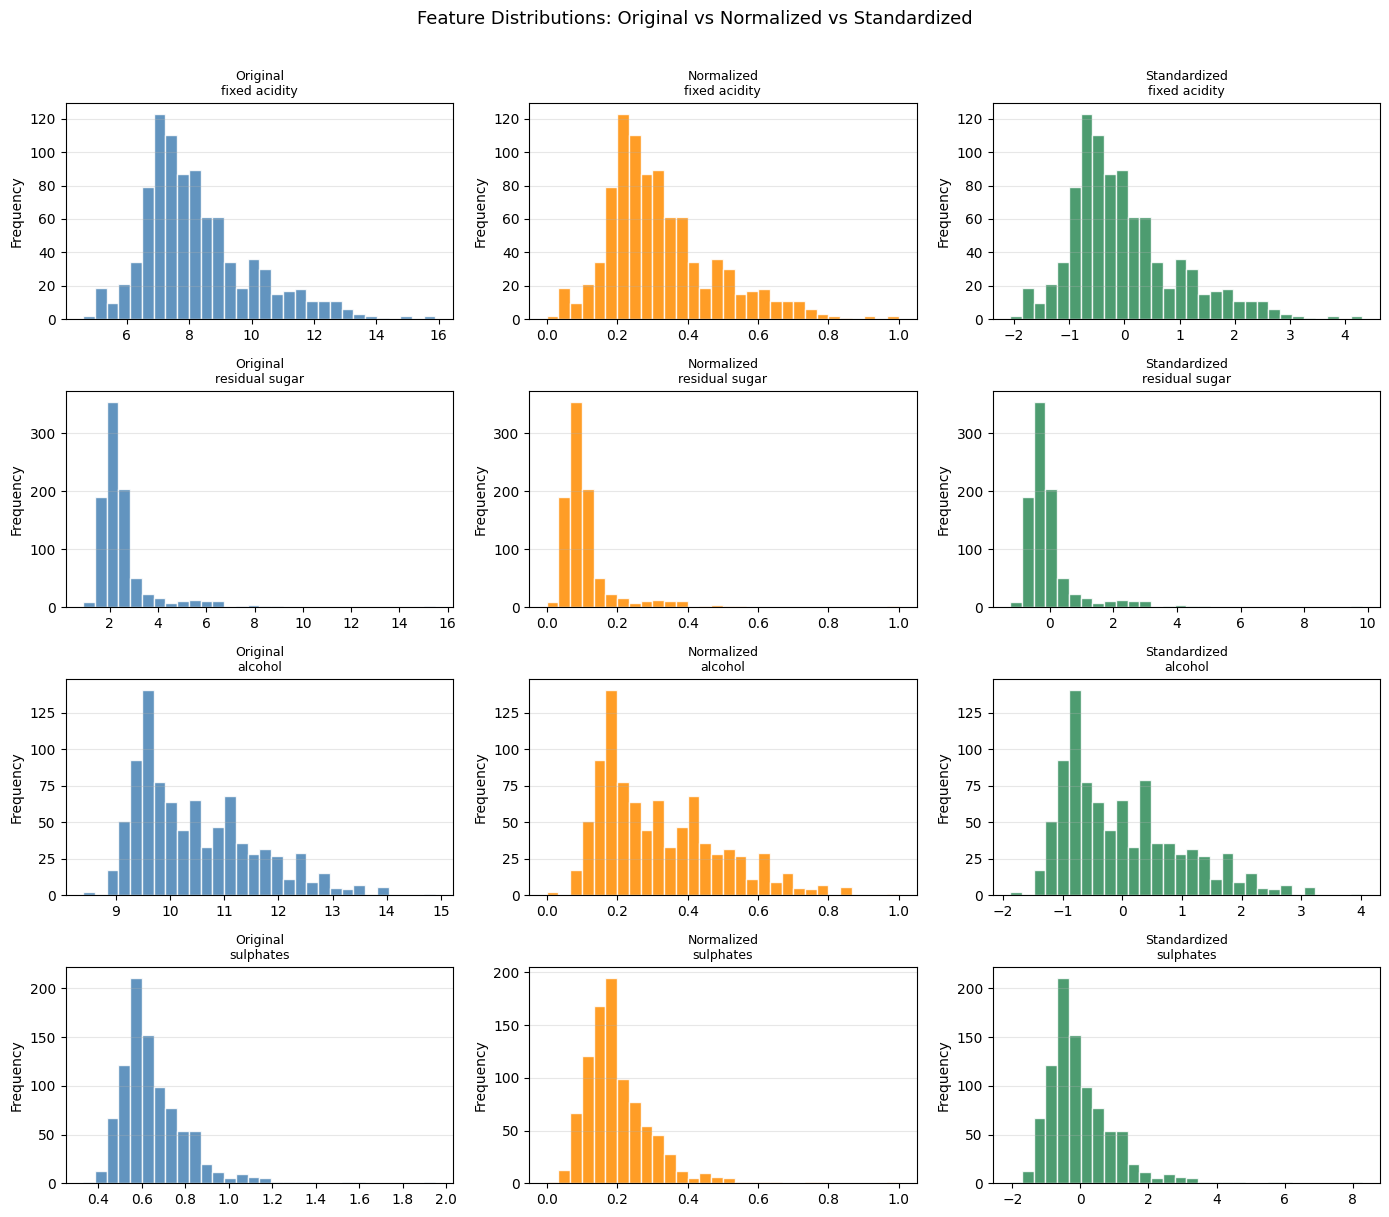


Distribution plot saved as task5_distributions.png


In [ ]:
# q5
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from scipy.stats import skew

df = pd.read_csv("WineQT_dataset.csv")
X = df.drop(columns=["quality", "Id"])
y = df["quality"]

print("=== Skewness Analysis ===")
print(f"{'Feature':<25} {'Skewness':>10}  Recommendation")
print("-" * 58)
for col in X.columns:
    s = skew(X[col])
    rec = (
        "Standardization"
        if abs(s) <= 0.5
        else ("Normalization" if abs(s) > 1 else "Either")
    )
    print(f"{col:<25} {s:>10.3f}  {rec}")

# --- Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print(f"\nTrain size: {X_train.shape} | Test size: {X_test.shape}")

# --- Normalization ---
norm = MinMaxScaler()
X_train_norm = norm.fit_transform(X_train)  # fit + transform on train
X_test_norm = norm.transform(X_test)  # only

norm_train_df = pd.DataFrame(X_train_norm, columns=X.columns)
print("\n[Normalization] Train set stats:")
print(norm_train_df.agg(["min", "max"]).round(4))


std = StandardScaler()
X_train_std = std.fit_transform(X_train)  # fit +
X_test_std = std.transform(X_test)  # only

std_train_df = pd.DataFrame(X_train_std, columns=X.columns)
print("\n[Standardization] Train set stats:")
print(std_train_df.agg(["mean", "std"]).round(4))


features_to_plot = ["fixed acidity", "residual sugar", "alcohol", "sulphates"]

fig, axes = plt.subplots(len(features_to_plot), 3, figsize=(14, 12))
fig.suptitle(
    "Feature Distributions: Original vs Normalized vs Standardized", fontsize=13, y=1.01
)

colors = ["steelblue", "darkorange", "seagreen"]
labels = ["Original", "Normalized", "Standardized"]

for i, feat in enumerate(features_to_plot):
    col_idx = list(X.columns).index(feat)
    data_sets = [
        X_train[feat].values,
        X_train_norm[:, col_idx],
        X_train_std[:, col_idx],
    ]
    for j, (data, color, label) in enumerate(zip(data_sets, colors, labels)):
        axes[i, j].hist(data, bins=30, color=color, edgecolor="white", alpha=0.85)
        axes[i, j].set_title(f"{label}\n{feat}", fontsize=9)
        axes[i, j].set_ylabel("Frequency")
        axes[i, j].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("task5_distributions.png", dpi=120, bbox_inches="tight")
plt.show()
print("\nDistribution plot saved as task5_distributions.png")

In [ ]:
# q6
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

df = pd.read_csv("adult_income_dataset.csv")

print(f"Dataset shape: {df.shape}")
cat_cols = df.select_dtypes(include="object").columns.tolist()
print(f"Categorical columns: {cat_cols}")

X = df.drop(columns=["income"])
y = df["income"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7)

X_train = X_train.copy()
X_test = X_test.copy()


le = LabelEncoder()
X_train["gender_label"] = le.fit_transform(X_train["gender"])

X_test["gender_label"] = (
    X_test["gender"]
    .map(dict(zip(le.classes_, le.transform(le.classes_))))
    .fillna(-1)
    .astype(int)
)

print("\n=== Label Encoding — gender ===")
print(dict(zip(le.classes_, le.transform(le.classes_))))
print(X_train[["gender", "gender_label"]].drop_duplicates())


edu_order = [
    [
        "Preschool",
        "1st-4th",
        "5th-6th",
        "7th-8th",
        "9th",
        "10th",
        "11th",
        "12th",
        "HS-grad",
        "Some-college",
        "Assoc-voc",
        "Assoc-acdm",
        "Bachelors",
        "Prof-school",
        "Masters",
        "Doctorate",
    ]
]

oe = OrdinalEncoder(
    categories=edu_order, handle_unknown="use_encoded_value", unknown_value=-1
)
X_train["education_ord"] = oe.fit_transform(X_train[["education"]])
X_test["education_ord"] = oe.transform(X_test[["education"]])

print("\n=== Ordinal Encoding — education ===")
edu_map = (
    X_train[["education", "education_ord"]]
    .drop_duplicates()
    .sort_values("education_ord")
)
print(edu_map.to_string(index=False))


ohe_train = pd.get_dummies(
    X_train[["occupation", "race"]], prefix=["occ", "race"], drop_first=False
)
ohe_test = pd.get_dummies(
    X_test[["occupation", "race"]], prefix=["occ", "race"], drop_first=False
)


ohe_test = ohe_test.reindex(columns=ohe_train.columns, fill_value=0)

X_train = pd.concat(
    [X_train.reset_index(drop=True), ohe_train.reset_index(drop=True)], axis=1
)
X_test = pd.concat(
    [X_test.reset_index(drop=True), ohe_test.reset_index(drop=True)], axis=1
)

print(f"\n=== One-Hot Encoding — occupation & race ===")
print(f"New OHE columns created: {len(ohe_train.columns)}")
print(f"Sample OHE columns: {list(ohe_train.columns[:6])}")
print(f"Train shape after OHE: {X_train.shape}")
print(f"Test  shape after OHE: {X_test.shape}")


print("\n=== Encoding Comparison (first 5 rows of training set) ===")
view_cols = [
    "gender",
    "gender_label",
    "education",
    "education_ord",
    "occupation",
    "occ_Adm-clerical",
    "occ_Craft-repair",
]
print(X_train[view_cols].head().to_string(index=False))

Dataset shape: (48842, 15)
Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country', 'income']

=== Label Encoding — gender ===
{'Female': np.int64(0), 'Male': np.int64(1)}
       gender  gender_label
42575    Male             1
21107  Female             0

=== Ordinal Encoding — education ===
   education  education_ord
   Preschool            0.0
     1st-4th            1.0
     5th-6th            2.0
     7th-8th            3.0
         9th            4.0
        10th            5.0
        11th            6.0
        12th            7.0
     HS-grad            8.0
Some-college            9.0
   Assoc-voc           10.0
  Assoc-acdm           11.0
   Bachelors           12.0
 Prof-school           13.0
     Masters           14.0
   Doctorate           15.0

=== One-Hot Encoding — occupation & race ===
New OHE columns created: 20
Sample OHE columns: ['occ_?', 'occ_Adm-clerical', 'occ_Armed-Forces', 'occ_Craft-